<a href="https://colab.research.google.com/github/sumratariq/Kics-Tasks/blob/main/lstm_vs_distilbert_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LSTM vs DistilBERT vs Fine-tuned DistilBERT
### Text classification (movie review: positive or negative)

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Run cells top to bottom.

We test three models on the **same** reviews:

| Stage | Model | Plain-language idea |
|---|---|---|
| 1 | **LSTM** | Small network trained from scratch. It knows nothing about English until it sees our data. |
| 2 | **DistilBERT (ready-made)** | A transformer already trained by someone else on a different sentiment dataset (SST-2). We use it as-is, with no training on our data. |
| 3 | **DistilBERT (fine-tuned)** | The same transformer idea, but we train it a bit more on our own reviews. |

At the end, everything is compared in one table and chart.

In [1]:
!pip install -q transformers datasets accelerate scikit-learn

import time, re, numpy as np, torch, torch.nn as nn
from collections import Counter
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import pipeline

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pdev = 0 if torch.cuda.is_available() else -1
print("Device:", dev)

results = {}   # we will store every model's scores here

Device: cuda


## Step 0: Shared data
All three models use the same 4,000 training reviews and the same 1,000 test reviews. The test reviews are never used for training, so the scores are honest.

In [2]:
ds = load_dataset("stanfordnlp/imdb")

full_train = ds["train"].shuffle(seed=42)
train = full_train.select(range(20000))           # model learns from these
val   = full_train.select(range(20000, 25000))    # we check progress on these
test  = ds["test"].shuffle(seed=42).select(range(5000))   # final exam, used once

train_texts, y_train = list(train["text"]), np.array(train["label"])
val_texts,   y_val   = list(val["text"]),   np.array(val["label"])
test_texts,  y_test  = list(test["text"]),  np.array(test["label"])
print(len(train_texts), "train /", len(val_texts), "validation /", len(test_texts), "test")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

20000 train / 5000 validation / 5000 test


## Stage 1: LSTM
**What an LSTM is, simply:** it reads a sentence one word at a time, from left to right (and right to left here), keeping a small "memory" of what it has seen so far. At the end, that memory is used to decide positive or negative.

Steps: build a word list → turn words into numbers → train.

In [3]:
MAX_LEN, VOCAB = 256, 20000

def tokens(t):
    return re.findall(r"[a-z']+", t.lower().replace("<br />", " "))

counter = Counter(w for t in train_texts for w in tokens(t))
vocab = {"<pad>": 0, "<unk>": 1}
for w, _ in counter.most_common(VOCAB - 2):
    vocab[w] = len(vocab)

def encode(t):
    ids = [vocab.get(w, 1) for w in tokens(t)][:MAX_LEN]
    return ids + [0] * (MAX_LEN - len(ids))

Xtr = torch.tensor([encode(t) for t in train_texts]); Ytr = torch.tensor(y_train)
Xva = torch.tensor([encode(t) for t in val_texts]);   Yva = torch.tensor(y_val)
Xte = torch.tensor([encode(t) for t in test_texts]);  Yte = torch.tensor(y_test)

train_dl = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr, Ytr), batch_size=64, shuffle=True)
val_dl   = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xva, Yva), batch_size=128)
test_dl  = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xte, Yte), batch_size=128)

In [4]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb=128, hid=128):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.4)
        self.fc   = nn.Linear(hid * 2, 2)

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1)
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(self.drop(h))

def lstm_predict(dl):
    model.eval(); preds = []
    with torch.no_grad():
        for xb, _ in dl:
            preds += model(xb.to(dev)).argmax(1).cpu().tolist()
    return np.array(preds)

model = LSTMClassifier(len(vocab)).to(dev)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

t0 = time.time()
for epoch in range(6):
    model.train(); total = 0
    for xb, yb in train_dl:
        xb, yb = xb.to(dev), yb.to(dev)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward(); opt.step()
        total += loss.item()
    val_acc = accuracy_score(y_val, lstm_predict(val_dl))
    print(f"Epoch {epoch+1}: loss {total/len(train_dl):.3f} | validation accuracy {val_acc:.3f}")
lstm_train_time = time.time() - t0

Epoch 1: loss 0.654 | validation accuracy 0.725
Epoch 2: loss 0.559 | validation accuracy 0.755
Epoch 3: loss 0.477 | validation accuracy 0.786
Epoch 4: loss 0.427 | validation accuracy 0.795
Epoch 5: loss 0.451 | validation accuracy 0.729
Epoch 6: loss 0.388 | validation accuracy 0.814


In [5]:
t0 = time.time()
preds = lstm_predict(test_dl)
results["LSTM (from scratch)"] = {
    "Accuracy": accuracy_score(y_test, preds),
    "F1": f1_score(y_test, preds),
    "Train time (s)": lstm_train_time,
    "Test time (s)": time.time() - t0,
}
print(results["LSTM (from scratch)"])

{'Accuracy': 0.8048, 'F1': 0.8228031953522149, 'Train time (s)': 69.69659090042114, 'Test time (s)': 0.38043856620788574}


### Stage 1 result
Look at the accuracy above. An LSTM learning from only 4,000 reviews usually lands somewhere in the 80s or lower. It has to learn what every word means from scratch, with very little data.

## Stage 2: DistilBERT, ready-made (no training from us)
This model was already trained by Hugging Face on a different sentiment dataset (SST-2). We just run it on our test reviews to see how well its existing knowledge carries over.

*Note: plain `distilbert-base-uncased` with no sentiment training would just guess randomly, because it has no classification head trained yet. That's why we use this ready-made sentiment version here.*

In [6]:
ready = pipeline("sentiment-analysis",
                 model="distilbert-base-uncased-finetuned-sst-2-english",
                 device=pdev, truncation=True, max_length=256)

t0 = time.time()
outs = ready(test_texts, batch_size=32)
test_time = time.time() - t0
preds = np.array([1 if o["label"] == "POSITIVE" else 0 for o in outs])

results["DistilBERT (ready-made)"] = {
    "Accuracy": accuracy_score(y_test, preds),
    "F1": f1_score(y_test, preds),
    "Train time (s)": 0.0,   # we did no training
    "Test time (s)": test_time,
}
print(results["DistilBERT (ready-made)"])

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

{'Accuracy': 0.8776, 'F1': 0.8755085435313262, 'Train time (s)': 0.0, 'Test time (s)': 45.65427899360657}


### Stage 2 result
Without any training from us, the transformer already does well because it learned language from huge amounts of text. It was trained on short sentences (SST-2), while IMDb reviews are long, so there is room to improve.

## Stage 3: Fine-tune DistilBERT on our reviews
**Fine-tuning, simply:** we start from a model that already understands English and teach it our specific task using our own labeled reviews. It's like hiring someone who already speaks the language and training them on your job.

In [7]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from datasets import Dataset

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)

def prep(texts, labels):
    d = Dataset.from_dict({"text": texts, "label": [int(l) for l in labels]})
    return d.map(lambda b: tok(b["text"], truncation=True, max_length=256), batched=True)

tr_ds, va_ds, te_ds = prep(train_texts, y_train), prep(val_texts, y_val), prep(test_texts, y_test)

ft_model = AutoModelForSequenceClassification.from_pretrained(
    name, num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1},
)

args = TrainingArguments(
    output_dir="ft_out",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    fp16=torch.cuda.is_available(),
    report_to="none",
    save_strategy="no",
)
trainer = Trainer(model=ft_model, args=args, train_dataset=tr_ds,
                  data_collator=DataCollatorWithPadding(tok))

t0 = time.time()
trainer.train()
ft_train_time = time.time() - t0

val_preds = trainer.predict(va_ds).predictions.argmax(axis=1)
print("Validation accuracy:", accuracy_score(y_val, val_preds))

# save so a Colab disconnect doesn't lose the trained model
ft_model.save_pretrained("ft_distilbert_20k")
tok.save_pretrained("ft_distilbert_20k")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

...

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.357839
1000,0.272695
1500,0.215701
2000,0.175508
2500,0.176722


Validation accuracy: 0.9094


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('ft_distilbert_20k/tokenizer_config.json', 'ft_distilbert_20k/tokenizer.json')

In [8]:
t0 = time.time()
logits = trainer.predict(te_ds).predictions
test_time = time.time() - t0
preds = logits.argmax(axis=1)

results["DistilBERT (fine-tuned)"] = {
    "Accuracy": accuracy_score(y_test, preds),
    "F1": f1_score(y_test, preds),
    "Train time (s)": ft_train_time,
    "Test time (s)": test_time,
}
print(results["DistilBERT (fine-tuned)"])

{'Accuracy': 0.9088, 'F1': 0.9103421156114825, 'Train time (s)': 257.78948640823364, 'Test time (s)': 9.627110719680786}


## Final comparison

,Accuracy,F1,Train time (s),Test time (s)
LSTM (from scratch),0.805,0.823,69.697,0.380
DistilBERT (ready-made),0.878,0.876,0.000,45.654
DistilBERT (fine-tuned),0.909,0.910,257.789,9.627


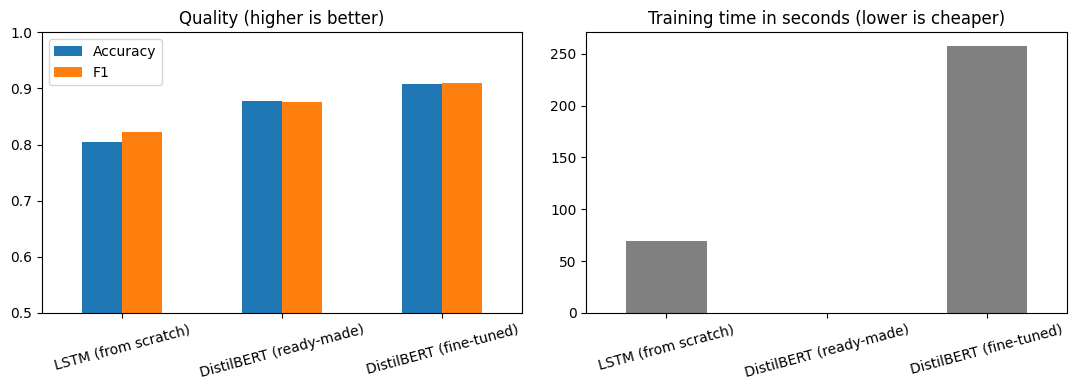

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(results).T
display(df.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df[["Accuracy", "F1"]].plot.bar(ax=ax[0], rot=15, ylim=(0.5, 1.0))
ax[0].set_title("Quality (higher is better)")
df["Train time (s)"].plot.bar(ax=ax[1], rot=15, color="gray")
ax[1].set_title("Training time in seconds (lower is cheaper)")
plt.tight_layout(); plt.show()

### How to read the results
- **Accuracy:** out of 100 reviews, how many it labeled correctly.
- **F1:** a score that balances catching positives and not mislabeling negatives. It is close to accuracy on this balanced data.
- **Train time:** how long learning took. The ready-made model needed none from us.
- **Test time:** how long it took to label the 1,000 test reviews.

**What you will typically see:** LSTM is the weakest because it starts with zero language knowledge. The ready-made DistilBERT is much better. The fine-tuned DistilBERT is usually best, since it has both general language knowledge and training on this exact kind of text. The trade-off is that transformers are heavier and slower than the LSTM.

Your exact numbers will differ a little from run to run.

## Bonus: try your own sentences on all three models

In [10]:
ft_pipe = pipeline("text-classification", model=ft_model, tokenizer=tok,
                   device=pdev, truncation=True, max_length=256)

def lstm_one(text):
    model.eval()
    x = torch.tensor([encode(text)]).to(dev)
    with torch.no_grad():
        return "POSITIVE" if model(x).argmax(1).item() == 1 else "NEGATIVE"

samples = [
    "An absolute masterpiece, I would watch it again tomorrow.",
    "I expected much more. Slow, dull and forgettable.",
    "Not bad, but not great either.",
    "The plot was terrible but somehow I loved every minute.",
]
for s in samples:
    print(s)
    print("  LSTM        :", lstm_one(s))
    print("  Ready-made  :", ready(s)[0]["label"])
    print("  Fine-tuned  :", ft_pipe(s)[0]["label"], "\n")

An absolute masterpiece, I would watch it again tomorrow.
  LSTM        : POSITIVE
  Ready-made  : POSITIVE
  Fine-tuned  : POSITIVE 

I expected much more. Slow, dull and forgettable.
  LSTM        : NEGATIVE
  Ready-made  : NEGATIVE
  Fine-tuned  : NEGATIVE 

Not bad, but not great either.
  LSTM        : NEGATIVE
  Ready-made  : NEGATIVE
  Fine-tuned  : NEGATIVE 

The plot was terrible but somehow I loved every minute.
  LSTM        : NEGATIVE
  Ready-made  : POSITIVE
  Fine-tuned  : POSITIVE 



In [11]:
torch.save(model.state_dict(), "lstm_20k.pt")
import json; json.dump(vocab, open("lstm_vocab.json", "w"))

!pip install -q shap lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 20.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [12]:
import shap, matplotlib.pyplot as plt
from lime.lime_text import LimeTextExplainer

pipe = pipeline("text-classification", model=ft_model, tokenizer=tok,
                device=pdev, top_k=None, truncation=True, max_length=256)

def proba_ft(texts):
    outs = pipe(list(texts), batch_size=32)
    return np.array([[d["score"] for d in sorted(o, key=lambda d: d["label"])] for o in outs])

def proba_lstm(texts):
    model.eval()
    x = torch.tensor([encode(t) for t in texts]).to(dev)
    with torch.no_grad():
        return torch.softmax(model(x), dim=1).cpu().numpy()

lime_exp = LimeTextExplainer(class_names=["NEGATIVE", "POSITIVE"])

review = "This movie was not bad at all, I loved the acting, although the ending felt a bit slow."
print("Fine-tuned DistilBERT:", proba_ft([review]).round(3))
print("LSTM:                 ", proba_lstm([review]).round(3))

Fine-tuned DistilBERT: [[0.056 0.944]]
LSTM:                  [[0.8 0.2]]


In [13]:
explainer = shap.Explainer(pipe)
shap_values = explainer([review])
shap.plots.text(shap_values[0, :, "POSITIVE"])

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  0%|          | 0/498 [00:00<?, ?it/s]

[(np.str_('loved'), 0.5657584279562604), (np.str_('not'), 0.334834795468527), (np.str_('felt'), -0.1320490470343658), (np.str_('at'), -0.10230051530615193), (np.str_('ending'), -0.09833506859493135), (np.str_('I'), 0.0827310698972791), (np.str_('bad'), -0.08046627446765209), (np.str_('was'), -0.07082116924488528)]


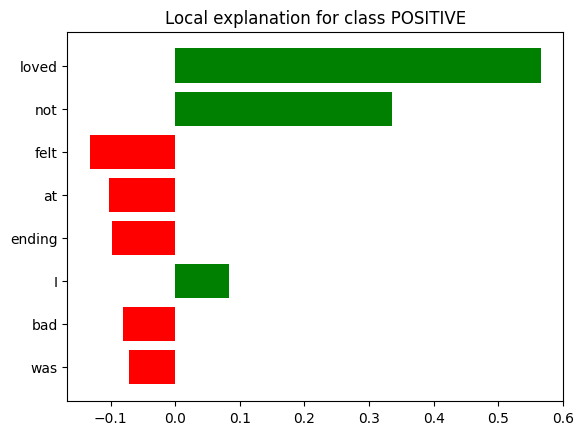

In [14]:
exp = lime_exp.explain_instance(review, proba_ft, num_features=8, num_samples=500)
print(exp.as_list())
exp.as_pyplot_figure(); plt.show()

LSTM says matter most:        [(np.str_('bad'), -0.4418572545584642), (np.str_('bit'), 0.19226599207491973), (np.str_('loved'), 0.1638472268577494), (np.str_('slow'), -0.15061570805549615), (np.str_('This'), -0.11175668379723197), (np.str_('although'), 0.09603861943711701), (np.str_('acting'), -0.0898047022763132), (np.str_('ending'), 0.08274463204298589)]
Transformer says matter most: [(np.str_('loved'), 0.5657584279562604), (np.str_('not'), 0.334834795468527), (np.str_('felt'), -0.1320490470343658), (np.str_('at'), -0.10230051530615193), (np.str_('ending'), -0.09833506859493135), (np.str_('I'), 0.0827310698972791), (np.str_('bad'), -0.08046627446765209), (np.str_('was'), -0.07082116924488528)]


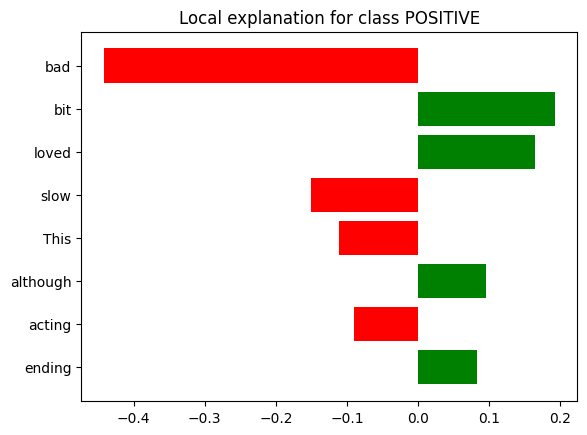

In [15]:
exp_lstm = lime_exp.explain_instance(review, proba_lstm, num_features=8, num_samples=500)
print("LSTM says matter most:       ", exp_lstm.as_list())
print("Transformer says matter most:", exp.as_list())
exp_lstm.as_pyplot_figure(); plt.show()

In [16]:
logits = trainer.predict(te_ds).predictions
ft_preds = logits.argmax(axis=1)
wrong = np.where(ft_preds != y_test)[0]
print(len(wrong), "mistakes out of", len(y_test))

# the 3 shortest mistakes are the easiest to read
for i in sorted(wrong, key=lambda i: len(test_texts[i]))[:3]:
    text = test_texts[i]
    true = "POSITIVE" if y_test[i] == 1 else "NEGATIVE"
    pred = "POSITIVE" if ft_preds[i] == 1 else "NEGATIVE"
    print(f"TRUE: {true} | MODEL SAID: {pred}\n{text}")
    e = lime_exp.explain_instance(text, proba_ft, num_features=8, num_samples=500)
    print("Word weights:", e.as_list(), "\n")

456 mistakes out of 5000
TRUE: NEGATIVE | MODEL SAID: POSITIVE
If it wasn't for the terrific music, I would not hesitate to give this cinematic underachievement 2/10. But the music actually makes me like certain passages, and so I give it 5/10.
Word weights: [(np.str_('But'), 0.2289932284815293), (np.str_('it'), 0.1569549347116234), (np.str_('me'), 0.15429188458653295), (np.str_('underachievement'), -0.14936887049762737), (np.str_('terrific'), 0.1408218922655627), (np.str_('music'), 0.13803669632311816), (np.str_('makes'), 0.1029342788114341), (np.str_('wasn'), -0.06536071107263178)] 

TRUE: POSITIVE | MODEL SAID: NEGATIVE
Goof: Factual error<br /><br />When Charlie walks out of the room to commit suicide he takes his gun with a silencer. After a few seconds we hear a loud bang from the same gun being fired.
Word weights: [(np.str_('error'), -0.10500532327394128), (np.str_('gun'), -0.06630473706729292), (np.str_('Goof'), -0.047506814151721546), (np.str_('fired'), -0.0364686620527817), 

In [17]:
from collections import defaultdict
agg = defaultdict(list)
short = [t for t in test_texts if len(t) < 600][:30]

for t in short:
    e = lime_exp.explain_instance(t, proba_ft, num_features=10, num_samples=300)
    for w, wt in e.as_list():
        agg[w].append(wt)

avg = {w: np.mean(v) for w, v in agg.items() if len(v) >= 2}
ranked = sorted(avg.items(), key=lambda kv: kv[1])
print("Words pushing toward NEGATIVE:", ranked[:12])
print("Words pushing toward POSITIVE:", ranked[-12:])
print("Suspicious tokens:", {w: avg[w] for w in ["br", "movie", "film"] if w in avg})

Words pushing toward NEGATIVE: [(np.str_('worst'), np.float64(-0.4230701150464589)), (np.str_('ludicrous'), np.float64(-0.17792651259015857)), (np.str_('boring'), np.float64(-0.150147056185538)), (np.str_('bad'), np.float64(-0.14313973149490486)), (np.str_('slow'), np.float64(-0.09034020173507112)), (np.str_('script'), np.float64(-0.0851171816362119)), (np.str_('no'), np.float64(-0.0730208798079948)), (np.str_('t'), np.float64(-0.0704788379568521)), (np.str_('effects'), np.float64(-0.06623203516141654)), (np.str_('not'), np.float64(-0.0627459249302248)), (np.str_('little'), np.float64(-0.05652983106105071)), (np.str_('plot'), np.float64(-0.05441631535075285))]
Words pushing toward POSITIVE: [(np.str_('it'), np.float64(0.06565213442301267)), (np.str_('and'), np.float64(0.0695938708564978)), (np.str_('great'), np.float64(0.07250252264606225)), (np.str_('film'), np.float64(0.07258954135976292)), (np.str_('I'), np.float64(0.07792170017381037)), (np.str_('highly'), np.float64(0.090652479289